# 06. Paper: TabPFN (3) 실험 결과와 한계 — 5절, 부록 A·B

논문: Hollmann, Müller, Eggensperger, Hutter, *TabPFN: A Transformer That Solves Small Tabular Classification Problems in a Second* (ICLR 2023), [arXiv:2207.01848](https://arxiv.org/abs/2207.01848).

[04 PFN 복습과 아키텍처](04_tabpfn_paper_architecture.ipynb)와 [05 표 데이터를 위한 prior](05_tabpfn_paper_prior.ipynb)에서 모델과 prior를 봤습니다. 이 노트북은 그렇게 학습한 TabPFN의 실험 결과(5절, 부록 B)와 논문이 직접 적은 한계(부록 A)를 정리하고, 마지막에 논문 전체를 표 하나로 모읍니다.

이 노트북에서 다루는 흐름:

1. 실험 결과 (5절, 부록 B)
2. 한계 (부록 A)
3. 정리

## `minipfn` 불러오기

`01_pfn`과 같은 방식입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from minipfn.models.row_transformer import RowTransformer
from minipfn.recipes import tabpfn_v1 as spec

## 1. 실험 결과 — 5절

### 1.1 toy 문제 — 5.1절

![TabPFN Figure 4](images/tabpfn_fig4.png)

*그림: 논문 Figure 4. feature 2개짜리 toy 데이터셋 4개(위부터 moons, circles, iris의 두 클래스, wine의 두 클래스)에서 튜닝하지 않은 분류기들의 결정 경계입니다. 색이 진할수록 확신이 큽니다.*

결정 트리와 CatBoost는 축에 평행한 계단 모양 경계를, kNN은 들쭉날쭉한 경계를 만듭니다. TabPFN의 경계는 매끄럽고, GP처럼 데이터에서 먼 곳에서는 확신이 낮아집니다(색이 옅어짐). circles처럼 두 클래스가 섞인 곳을 빼면 원 모양도 확신 있게 맞힙니다. 이 그림은 이 저장소에서 아직 재현하지 않았습니다.

### 1.2 실험 설정 — 5.2절

- **데이터셋**: OpenML-CC18 중 샘플 2,000개(학습 1,000개), feature 100개, 클래스 10개 이하인 30개입니다. 본문(Figure 5, Table 1)은 이 중 수치형 feature만 있고 결측값이 없는 18개만 봅니다. prior를 이런 데이터셋에 맞춰 개발했기 때문입니다. 나머지를 포함한 30개 결과는 부록 B.1에 있습니다.
- **baseline**: KNN, 로지스틱 회귀, GBDT 세 개(XGBoost, LightGBM, CatBoost)는 5-fold 교차검증으로 하이퍼파라미터를 무작위 탐색합니다. AutoML 두 개(AutoGluon, Auto-sklearn 2.0)와 딥러닝 두 개(Regularization Cocktails, SAINT)도 비교합니다.
- **프로토콜**: 데이터셋마다 split 5개(학습 50%, 테스트 50%)이고, 지표는 ROC AUC(다중 클래스는 one-vs-one)입니다. baseline에는 30초부터 1시간까지 시간 예산을 줍니다.
- **TabPFN**: 튜닝 없이 앙상블 32개(TabPFN)와 앙상블 없이 forward pass 한 번(TabPFN n.e.)을 봅니다.

### 1.3 결과 — Table 1

18개 데이터셋에서 baseline에 1시간을 준 결과입니다. 논문 Table 1의 값을 옮겼습니다.

,평균 ROC AUC,평균 accuracy,평균 CE,시간 (s)
LightGBM,0.920000,0.862000,0.750000,3280
CatBoost,0.924000,0.864000,0.747000,3746
XGBoost,0.924000,0.866000,0.759000,3364
Auto-sklearn 2.0,0.929000,0.870000,0.813000,3601
AutoGluon,0.930000,0.881000,0.714000,3077
TabPFN n.e.,0.932000,0.873000,0.727000,0.0519
TabPFN,0.934000,0.879000,0.716000,0.6172
TabPFN + AutoGluon,0.934000,0.886000,0.711000,3077


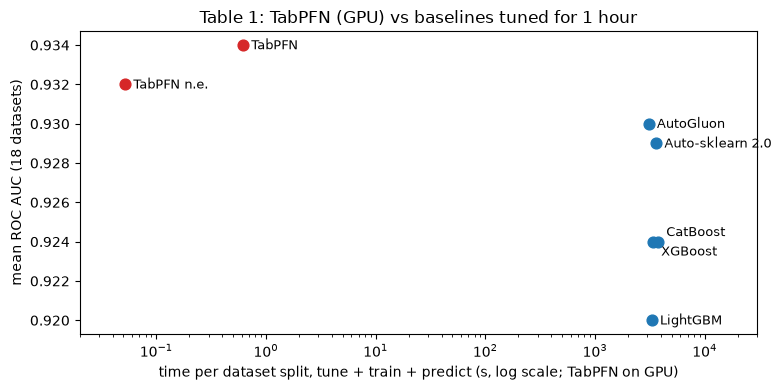

In [3]:
table1 = pd.DataFrame(
    {
        "평균 ROC AUC": [0.920, 0.924, 0.924, 0.929, 0.930, 0.932, 0.934, 0.934],
        "평균 accuracy": [0.862, 0.864, 0.866, 0.870, 0.881, 0.873, 0.879, 0.886],
        "평균 CE": [0.750, 0.747, 0.759, 0.813, 0.714, 0.727, 0.716, 0.711],
        # 튜닝 + 학습 + 예측 시간. baseline은 CPU, TabPFN은 GPU (CPU 시간은 아래 셀)
        "시간 (s)": [3280, 3746, 3364, 3601, 3077, 0.0519, 0.6172, 3077],
    },
    index=[
        "LightGBM",
        "CatBoost",
        "XGBoost",
        "Auto-sklearn 2.0",
        "AutoGluon",
        "TabPFN n.e.",
        "TabPFN",
        "TabPFN + AutoGluon",
    ],
)
display(table1.style.format({"시간 (s)": "{:g}"}))

# 라벨이 겹치지 않도록 점마다 글자 위치를 조금씩 옮긴다
label_offsets = {"CatBoost": (6, 4), "XGBoost": (6, -10)}
fig, ax = plt.subplots(figsize=(8, 4))
for name, row in table1.drop(index="TabPFN + AutoGluon").iterrows():
    is_tabpfn = name.startswith("TabPFN")
    ax.scatter(row["시간 (s)"], row["평균 ROC AUC"], s=60, color="C3" if is_tabpfn else "C0")
    offset = label_offsets.get(name, (6, -3))
    ax.annotate(
        name,
        (row["시간 (s)"], row["평균 ROC AUC"]),
        textcoords="offset points",
        xytext=offset,
        fontsize=9,
    )
ax.set_xscale("log")
ax.set_xlim(0.02, 30_000)
ax.set_xlabel("time per dataset split, tune + train + predict (s, log scale; TabPFN on GPU)")
ax.set_ylabel("mean ROC AUC (18 datasets)")
ax.set_title("Table 1: TabPFN (GPU) vs baselines tuned for 1 hour")
plt.tight_layout()
plt.show()

TabPFN은 GPU에서 1초 안에 평균 ROC AUC 0.934를 내서, 1시간 튜닝한 AutoGluon(0.930)과 Auto-sklearn 2.0(0.929)보다 조금 높고, 튜닝한 GBDT(0.920~0.924)보다는 확실히 높습니다. 앙상블 없이 forward pass 한 번만 해도 0.932입니다. TabPFN과 AutoGluon의 예측을 평균하면 accuracy와 CE가 가장 좋아집니다. 두 방법이 잘하는 데이터셋이 서로 달라서 오류의 상관이 낮기 때문입니다(부록 Figure 11).

초록의 "230배, 5,700배 빠르다"는 TabPFN n.e.를 5분 예산의 가장 강한 baseline과 비교한 값입니다(5.2절). 두 성능이 비슷하므로 시간만 나누면 됩니다.

In [4]:
baseline_budget = 5 * 60  # 5분 예산 baseline이 TabPFN n.e.와 비슷한 성능을 낸다 (5.2절)
tabpfn_ne_cpu = 1.301  # Table 1, TabPFN n.e.의 CPU 시간 (s)
tabpfn_ne_gpu = 0.0519  # Table 1, TabPFN n.e.의 GPU 시간 (s)
print(f"CPU: {baseline_budget / tabpfn_ne_cpu:.0f}배")
print(f"GPU: {baseline_budget / tabpfn_ne_gpu:,.0f}배")

CPU: 231배
GPU: 5,780배


이 저장소에서 논문 규모로 학습한 모델은 같은 18개 데이터셋에서 0.932(앙상블 없이 0.928)를 냈습니다. 어떻게 학습하고 평가했는지는 [`07_tabpfn_reproduction`](07_tabpfn_reproduction.ipynb)에 있습니다.

이 값들은 데이터셋 평균입니다. 논문도 강조하듯 모든 데이터셋에서 이기는 방법은 없고, 기본값 baseline에 지는 데이터셋도 있습니다.

### 1.4 그 밖의 결과 — 5.2절, 부록 B

| 실험 | 결과 | 이 저장소 |
|---|---|---|
| 30개 데이터셋 (B.1, Table 2) | 범주형 feature나 결측값이 있는 데이터셋까지 넣으면 TabPFN 0.894, AutoGluon 0.895로 우위가 사라진다 | 아직 |
| 데이터셋 특성별 (B.1, Figure 6) | 범주형 feature와 결측값이 없을 때 특히 강하다. 이진·다중 클래스는 비슷하다 | 아직 |
| OpenML-AutoML Benchmark (B.2) | 데이터셋당 CPU 4.4초로 60분 baseline들보다 평균 CE와 accuracy가 좋다 | 아직 |
| 학습 때보다 큰 데이터셋 (Figure 10) | 학습 때 최대 1,024행만 봤지만 학습 행 5,000개까지 성능이 평평해지지 않고 오른다 | 아직 |
| 귀납 편향 (B.3) | 매끄러운 함수를 선호하고, 무의미한 feature가 늘면 성능이 떨어지며, feature 회전에는 GBDT보다 덜 민감하다 | 아직 |
| prior ablation (B.4, Table 4) | SCM 0.881, BNN 0.865, 둘 섞기 0.883 | 아직 ([05](05_tabpfn_paper_prior.ipynb) 3절 표) |
| 검증 데이터셋 149개 (B.5) | 수치형 데이터셋에서 강하다는 결론이 유지된다 | 아직 |

## 2. 한계 — 부록 A

논문이 직접 적은 한계는 다섯 가지입니다.

**1. 비용이 학습 행 수의 제곱으로 늘어납니다.** attention 점수가 $n^2 + n \cdot m$개이기 때문입니다. 논문은 10만 행이 넘으면 당시 소비자용 GPU에서 추론이 어렵다고 적었습니다. 점수 행렬을 메모리에 다 만든다고 하면 층 하나에 필요한 크기는 다음과 같습니다(head 4개, fp16 기준).

In [5]:
rows = []
for n in [1_000, 10_000, 100_000]:
    m = n  # 테스트 행도 같은 수
    scores = spec.NHEAD * (n**2 + n * m)  # head 4개의 attention 점수
    rows.append(
        {
            "학습 행 n": f"{n:,}",
            "테스트 행 m": f"{m:,}",
            "점수 개수": f"{scores:,}",
            "fp16 메모리": f"{scores * 2 / 1e9:,.2f} GB",
        }
    )
display(pd.DataFrame(rows))

,학습 행 n,테스트 행 m,점수 개수,fp16 메모리
0,"1,000","1,000","8,000,000",0.02 GB
1,"10,000","10,000","800,000,000",1.60 GB
2,"100,000","100,000","80,000,000,000",160.00 GB


행 수가 10배 늘면 메모리는 100배 늘어납니다. 요즘 쓰는 flash attention 같은 커널은 점수 행렬을 통째로 만들지 않아 메모리는 줄지만, 계산량은 여전히 제곱으로 늘어납니다.

**2. feature 100개, 클래스 10개가 상한입니다.** `x_encoder`의 입력 크기와 decoder의 출력 크기가 고정되어 있기 때문입니다.

In [6]:
paper_model = RowTransformer(**spec.PAPER_MODEL)  # 논문 크기 (recipes/tabpfn_v1.py)
print("x_encoder 입력 크기 (최대 feature 수):", paper_model.x_encoder.in_features)
print("decoder 출력 크기 (최대 클래스 수):  ", paper_model.decoder[-1].out_features)

x_encoder 입력 크기 (최대 feature 수): 100
decoder 출력 크기 (최대 클래스 수):   10


**3. 범주형 feature와 결측값에 약합니다.** prior를 수치형 데이터셋에 맞춰 개발했기 때문입니다. 수치형 18개에서는 TabPFN(0.934)이 AutoGluon(0.930)보다 높지만, 30개 전체에서는 0.894와 0.895로 비슷해집니다(Table 2).

**4. 무의미한 feature에 약합니다.** prior에 정보 없는 feature가 많은 데이터셋이 드물어서, 이런 feature를 더하면 성능이 떨어집니다(B.3.2). LightGBM은 거의 영향을 받지 않습니다.

**5. 예측만 보면 baseline이 더 빠를 수 있습니다.** baseline은 학습과 예측을 따로 하지만 TabPFN은 둘을 forward pass 한 번에 같이 합니다. 그래서 학습이 끝난 baseline의 예측 시간만 비교하면, 앙상블 32개를 쓰는 TabPFN(0.62초)은 GBDT(0.02~0.08초)보다 느립니다. 앙상블 없는 TabPFN은 GBDT와 비슷합니다(Table 2, 30개 데이터셋 기준).

| | 예측 시간 (s) |
|---|---|
| CatBoost | 0.017 |
| XGBoost | 0.069 |
| LightGBM | 0.082 |
| TabPFN n.e. (학습 + 예측, GPU) | 0.052 |
| TabPFN (학습 + 예측, GPU) | 0.617 |
| Auto-sklearn 2.0 | 1.224 |
| AutoGluon | 21.18 |

후속 논문인 TabPFN v2(Hollmann et al., *Nature* 2025)는 prior와 구조를 바꿔 더 큰 데이터셋과 범주형 feature, 결측값을 다루도록 확장했습니다. 그 내용은 [`03_tabpfn_v2`](../03_tabpfn_v2/05_paper_walkthrough_model_and_training.ipynb)에서 다룹니다.

## 3. 정리

논문 전체를 노트북 세 개([04](04_tabpfn_paper_architecture.ipynb), [05](05_tabpfn_paper_prior.ipynb), 이 노트북)에 나눠 봤습니다. 논문 절마다 핵심과 코드를 모으면 다음과 같습니다.

| 논문 | 핵심 | 이 저장소 코드 |
|---|---|---|
| 2절 | PFN과 같은 손실로 prior의 PPD를 근사한다 | `spec.train_tabpfn`, `losses.classification_loss` |
| 3절, E.2 | 테스트 행은 학습 행에만 attend한다 ($n^2 + n \cdot m$) | `row_transformer.RowTransformerLayer._attend` |
| E.2 | feature를 100열까지 0으로 채우고 $100/k$배 한다 | `transforms.scaling.PadFeatures`, `rotation_ensemble._Preprocessor` |
| 3절, C.2.6 | 열 회전, 클래스 회전, power transform으로 앙상블 32개 | `spec.TabPFNv1Classifier` (`rotation_ensemble.RotationEnsembleClassifier`) |
| 4.1, 4.2 | 하이퍼파라미터도 분포에서 뽑고, 작은 그래프가 자주 나오게 한다 | `spec.MLP_HYPERPARAMETERS`, `prior_bag.sample_group_hyperparameters` |
| 4.3, 4.4 | SCM과 BNN을 반씩 섞는다 (v1은 GP도 4%) | `generators.mlp.sample_mlp_dataset`, `generators.gp.sample_gp_tables` |
| 4.5 | 연속값 target을 무작위 경계로 잘라 불균형한 클래스로 만든다 | `transforms.classes.multiclass_rank` |
| 5절 | 18개 데이터셋에서 1시간 튜닝한 AutoML과 비슷한 성능을 1초 안에 | `cc18.evaluate_methods`, [`07_tabpfn_reproduction`](07_tabpfn_reproduction.ipynb) |

이 행 단위 구조가 v2부터 3.5까지 어떻게 바뀌는지는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 모았습니다. v2는 토큰을 셀 단위로 바꾸고, 3은 셀을 행 벡터로 압축한 뒤 다시 v1처럼 행끼리 in-context learning을 합니다.

다음 노트북 [`07_tabpfn_reproduction`](07_tabpfn_reproduction.ipynb)에서는 이 구성으로 논문 규모의 TabPFN을 학습하고 Table 1과 비교합니다.